In [27]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = 'MIG-f80e9374-504a-571b-bac0-6fb00750db4c'
import sys
#sys.path.insert(0,'/users/kobbad/feat_leakage/deepSEA_negatives')
from model import Beluga
import torch
import pandas as pd
from bpnetlite.io import extract_loci
from tangermeme.ersatz import dinucleotide_shuffle
from tangermeme.ersatz import substitute, multisubstitute
import torch
from torch import nn
from tangermeme.deep_lift_shap import deep_lift_shap
from tangermeme.utils import random_one_hot, characters
from tangermeme.ersatz import substitute
from matplotlib import pyplot as plt
from tangermeme.plot import plot_logo
from torch.utils.data import Dataset, DataLoader
import random
from model import SyntheticMotifCountDataset
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import matplotlib
from sklearn.metrics import r2_score
from tqdm import tqdm
from fuzzywuzzy import fuzz
from scipy.stats import wilcoxon, pearsonr
from statsmodels.stats.multitest import multipletests
import importlib
import model
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import roc_auc_score, roc_curve, auc
importlib.reload(model)

from model import extract_activations_batch, BelugaProbeWithClampedActivations, SyntheticMotifClassificationDataset

In [2]:
# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

# Load the original Beluga model
print("Loading original Beluga model...")
mdl = Beluga()
mdl.load_state_dict(torch.load('../deepSEA_negatives/deepsea.beluga.pth', map_location=device))


Using device: cuda
Loading original Beluga model...


<All keys matched successfully>

In [18]:
annots = pd.read_excel("../ap1_counting/data/motif_annotations.xlsx",engine='openpyxl')
archetypes = pd.read_csv("../ap1_counting/data/motifs.tsv", sep="\t")

all_motifs = archetypes[archetypes["Motif"].isin(annots["Seed_motif"])][["Cluster_ID","Consensus", "Motif"]]

consensus_to_cluster = all_motifs.set_index("Consensus")["Motif"].to_dict()
motif_to_seq = {v:k for k,v in consensus_to_cluster.items()}

ctcf_motif = motif_to_seq['CTCFL_HUMAN.H11MO.0.A']
ap1_motif = "ATGAGTCAC"
ctcf_motif, ap1_motif

('GCCGCCAGGGGGCGCCG', 'ATGAGTCAC')

In [13]:
X = random_one_hot((100, 4, 2000)).type(torch.float32)
X_ctcf = substitute(X, ctcf_motif)
X_ap1 = substitute(X, ap1_motif)

In [15]:
X_ap1[0:10].shape

torch.Size([10, 4, 2000])

In [22]:
layer_name = 'model.0.14'

activations = extract_activations_batch(
    model=mdl,
    layer_name='model.0.14',
    input_data_list=X,
    batch_size=32
)

activations_ap1 = extract_activations_batch(
    model=mdl,
    layer_name='model.0.14',
    input_data_list=X_ap1,
    batch_size=32
)


activations_ctcf = extract_activations_batch(
    model=mdl,
    layer_name='model.0.14',
    input_data_list=X_ctcf,
    batch_size=32
)


In [28]:
ctcf_net_activations = [(activations_ctcf[i] - activations[i]).flatten() for i in range(len(activations))]
ap1_net_activations = [(activations_ap1[i] - activations[i]).flatten() for i in range(len(activations))]

In [30]:
ctcf_activations = np.mean(ctcf_net_activations, axis=0)
ap1_activations = np.mean(ap1_net_activations, axis=0)


pearsonr(ctcf_activations, ap1_activations)

PearsonRResult(statistic=np.float32(0.27233183), pvalue=np.float64(0.0))

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

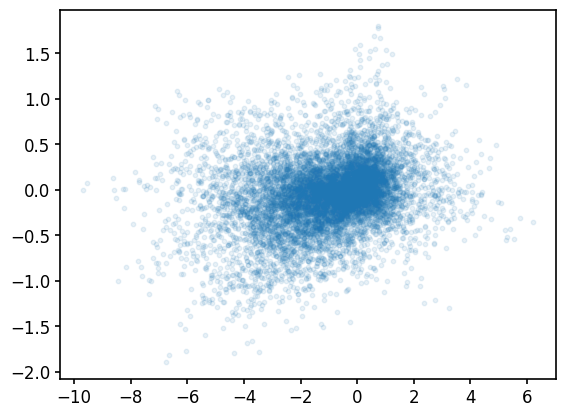

In [36]:
plt.scatter(ctcf_activations, ap1_activations, s=10, alpha=0.1);

Correlation: r = 0.2723, p = 0.00e+00


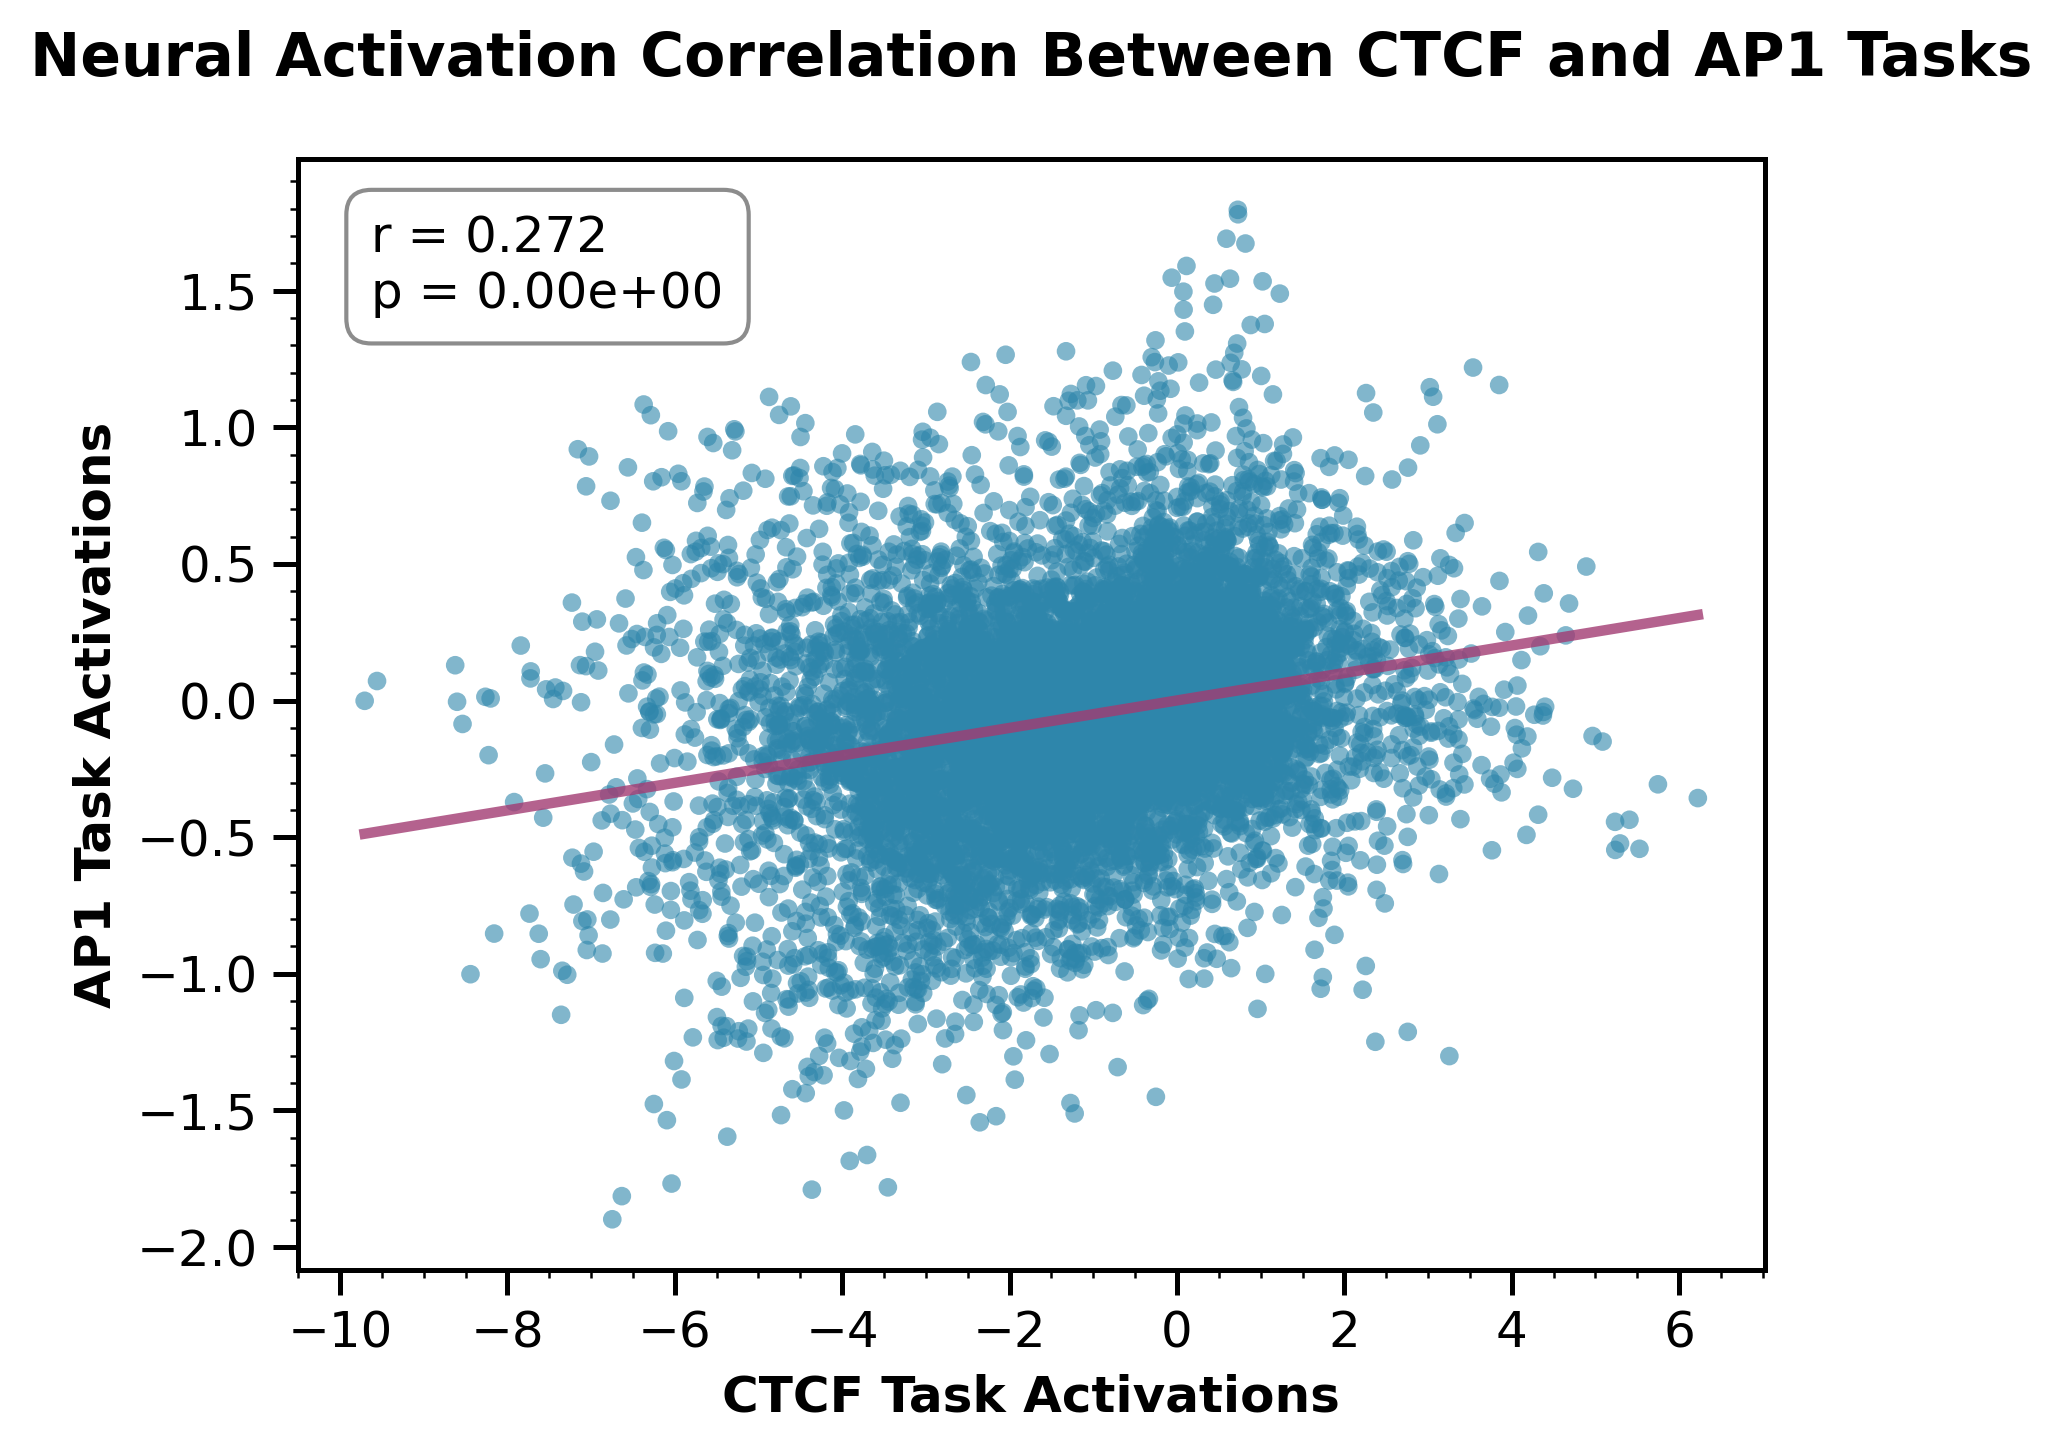

In [37]:
from sklearn.linear_model import LinearRegression

# Set matplotlib for publication quality
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['xtick.major.width'] = 1.2
plt.rcParams['ytick.major.width'] = 1.2

# Convert to numpy arrays and flatten
x_data = np.array(ctcf_activations).flatten()
y_data = np.array(ap1_activations).flatten()

# Calculate correlation
r_value, p_value = pearsonr(x_data, y_data)

# Fit linear regression for trend line
reg = LinearRegression()
X_reshaped = x_data.reshape(-1, 1)
reg.fit(X_reshaped, y_data)

# Generate trend line points
x_trend = np.linspace(x_data.min(), x_data.max(), 100)
y_trend = reg.predict(x_trend.reshape(-1, 1))

# Create the figure
fig, ax = plt.subplots(figsize=(6, 5), dpi=300)

# Create scatter plot
scatter = ax.scatter(x_data, y_data, 
                    alpha=0.6, 
                    s=20,
                    c='#2E86AB',
                    edgecolors='none')

# Add trend line
ax.plot(x_trend, y_trend, 
        color='#A23B72',
        linewidth=2.5,
        alpha=0.8)

# Add correlation text
ax.text(0.05, 0.95, 
        f'r = {r_value:.3f}\np = {p_value:.2e}',
        transform=ax.transAxes,
        verticalalignment='top',
        bbox=dict(boxstyle='round,pad=0.5', 
                 facecolor='white', 
                 edgecolor='gray',
                 alpha=0.9))

# Customize axes
ax.set_xlabel('CTCF Task Activations', fontweight='bold')
ax.set_ylabel('AP1 Task Activations', fontweight='bold')
ax.set_title('Neural Activation Correlation Between CTCF and AP1 Tasks', fontweight='bold', pad=20)

# Add grid
ax.grid(False)

# Customize spines
for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color('black')

# Set tick parameters
ax.tick_params(direction='out', length=6, width=1.2, colors='black', which='major')
ax.minorticks_on()

# Tight layout
plt.tight_layout()

# Save as PDF and SVG
plt.savefig('ctcf_ap1_correlation_no_grid.pdf', 
            format='pdf',
            dpi=300,
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

plt.savefig('ctcf_ap1_correlation_no_grid.svg',
            format='svg',
            dpi=300,
            bbox_inches='tight',
            facecolor='white',
            edgecolor='none')

print(f"Correlation: r = {r_value:.4f}, p = {p_value:.2e}")
plt.show()

### ablation experiments

steps:
1. make a minimal dataset with both pos and neg
2. see if the model can overfit to it with BCELoss

ablate neurons activated by CTCF

In [ ]:
import model as m
# Load the original Beluga model
device = 'cuda'

print("Loading original Beluga model...")
mdl = m.Beluga()
mdl.load_state_dict(torch.load('../deepSEA_negatives/deepsea.beluga.pth', map_location=device))


In [22]:
# --- Build the probe and set modes ---
mdl_probe = BelugaProbeWithClampedActivations(mdl, None, 1).to(device)
mdl_probe.beluga_model.eval()   # freeze backbone behavior (no dropout randomness)
mdl_probe.train()               # keep the probe in train mode

loss_fn   = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(mdl_probe.parameters(), lr=1e-3)

# --- Make datasets (no leakage across splits) ---
full = SyntheticMotifClassificationDataset(N=14_000, L=2000, motif="ATGAGTCAC", seed=42)
n_train, n_val, n_test = 10_000, 2_000, 2_000
train_set, val_set, test_set = random_split(full, [n_train, n_val, n_test],
                                            generator=torch.Generator().manual_seed(123))

def make_loader(ds, bs, shuffle):
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=4,
                      pin_memory=True, persistent_workers=True)

train_loader = make_loader(train_set, 32, True)
val_loader   = make_loader(val_set,   64, False)
test_loader  = make_loader(test_set,  64, False)

# --- Eval helper: returns (avg_loss, auc) ---
@torch.no_grad()
def evaluate(model, loader):
    model.eval()  # probe to eval during evaluation
    all_logits, all_targets, total_loss, n_batches = [], [], 0.0, 0
    for X, y in loader:
        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True).unsqueeze(-1)  # (B,1), float {0,1}
        logits = model(X)                                  # (B,1), raw logits
        loss = loss_fn(logits, y)
        total_loss += loss.item()
        n_batches += 1
        all_logits.append(logits.detach().float().cpu())
        all_targets.append(y.detach().float().cpu())
    logits = torch.cat(all_logits, dim=0).squeeze(1).numpy()
    targets = torch.cat(all_targets, dim=0).squeeze(1).numpy()
    # AUC can fail if only one class present; guard it:
    auc = roc_auc_score(targets, logits)  # logits OK; monotonic w/ sigmoid
    model.train()  # restore probe to train mode after eval
    return total_loss / max(1, n_batches), auc

# --- Test AUC BEFORE training ---
test_loss0, test_auc0 = evaluate(mdl_probe, test_loader)
print(f"[Before training] Test loss: {test_loss0:.4f} | Test AUC: {test_auc0:.4f}")

# --- Training with early stopping on val AUC ---
num_epochs = 20
patience   = 5   # stop if val AUC hasn't improved for 5 epochs
best_state = None
best_val_auc = -float("inf")
epochs_no_improve = 0

history = {"train_loss": [], "val_loss": [], "val_auc": []}

for epoch in range(1, num_epochs + 1):
    # ----- train one epoch -----
    mdl_probe.train()  # train mode for the probe
    running = 0.0
    nb = 0
    for X, y in train_loader:
        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True).unsqueeze(-1)  # (B,1)
        optimizer.zero_grad(set_to_none=True)
        logits = mdl_probe(X)         # (B,1)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()
        running += loss.item()
        nb += 1
    train_loss = running / max(1, nb)

    # ----- validate -----
    val_loss, val_auc = evaluate(mdl_probe, val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_auc"].append(val_auc)

    print(f"Epoch {epoch:02d} | train_loss={train_loss:.4f} "
          f"| val_loss={val_loss:.4f} | val_auc={val_auc:.4f}")

    # ----- early stopping on val AUC -----
    improved = (val_auc > best_val_auc) or (epoch == 1 and (val_auc == best_val_auc))
    if improved:
        best_val_auc = val_auc
        epochs_no_improve = 0
        # save a lightweight copy of the probe’s parameters
        best_state = {k: v.detach().cpu().clone() for k, v in mdl_probe.state_dict().items()}
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch} (no val AUC improvement for {patience} epochs).")
            break

# --- Load best weights (by val AUC) ---
if best_state is not None:
    mdl_probe.load_state_dict(best_state, strict=True)

# --- Test AUC AFTER training (best checkpoint) ---
test_loss1, test_auc1 = evaluate(mdl_probe, test_loader)
print(f"[After training]  Test loss: {test_loss1:.4f} | Test AUC: {test_auc1:.4f}")

[Before training] Test loss: 0.6971 | Test AUC: 0.4217
Epoch 01 | train_loss=0.5893 | val_loss=0.5418 | val_auc=0.8478
Epoch 02 | train_loss=0.5101 | val_loss=0.5908 | val_auc=0.8561
Epoch 03 | train_loss=0.4845 | val_loss=0.5259 | val_auc=0.8762
Epoch 04 | train_loss=0.4838 | val_loss=0.5257 | val_auc=0.8716
Epoch 05 | train_loss=0.4824 | val_loss=0.4863 | val_auc=0.8748
Epoch 06 | train_loss=0.4835 | val_loss=0.5302 | val_auc=0.8710
Epoch 07 | train_loss=0.4790 | val_loss=0.4543 | val_auc=0.8785
Epoch 08 | train_loss=0.4732 | val_loss=0.5675 | val_auc=0.8611
Epoch 09 | train_loss=0.4904 | val_loss=0.5474 | val_auc=0.8905
Epoch 10 | train_loss=0.4849 | val_loss=0.4843 | val_auc=0.8832
Epoch 11 | train_loss=0.4708 | val_loss=0.4882 | val_auc=0.8980
Epoch 12 | train_loss=0.4677 | val_loss=0.4967 | val_auc=0.8793
Epoch 13 | train_loss=0.4676 | val_loss=0.5325 | val_auc=0.8780
Epoch 14 | train_loss=0.4620 | val_loss=0.5066 | val_auc=0.8842
Epoch 15 | train_loss=0.4924 | val_loss=0.4774 | 

In [28]:
@torch.no_grad()
def collect_logits_targets(model, loader, device):
    model.eval()  # probe to eval; backbone already set to eval
    logits_list, targets_list = [], []
    for X, y in loader:
        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True).float().unsqueeze(-1)  # (B,1)
        logits = model(X).float()  # (B,1) raw logits
        logits_list.append(logits.cpu())
        targets_list.append(y.cpu())
    logits = torch.cat(logits_list, dim=0).squeeze(1).numpy()
    targets = torch.cat(targets_list, dim=0).squeeze(1).numpy()
    return logits, targets

def roc_curve_and_auc(logits, targets):
    # Guard against single-class edge cases
    if len(np.unique(targets)) < 2:
        return None, None, None
    fpr, tpr, _ = roc_curve(targets, logits)  # logits OK
    return fpr, tpr, auc(fpr, tpr)


In [30]:
# --- Make datasets (no leakage across splits) ---
test_ctcf = SyntheticMotifClassificationDataset(N=2_000, L=2000, motif=ctcf_motif, seed=42)
test_ctcf_loader  = make_loader(test_ctcf,  64, False)

ap1_test_logits, ap1_labels = collect_logits_targets(mdl_probe, test_loader, device)
ctcf_test_logits, ctcf_labels = collect_logits_targets(mdl_probe, test_ctcf_loader, device)

In [31]:
ap1_fpr, ap1_tpr, ap1_auc = roc_curve_and_auc(ap1_test_logits, ap1_labels)
ctcf_fpr, ctcf_tpr, ctcf_auc = roc_curve_and_auc(ctcf_test_logits, ctcf_labels)

ap1_auc, ctcf_auc

(0.8816171878752942, 0.6544479999999999)

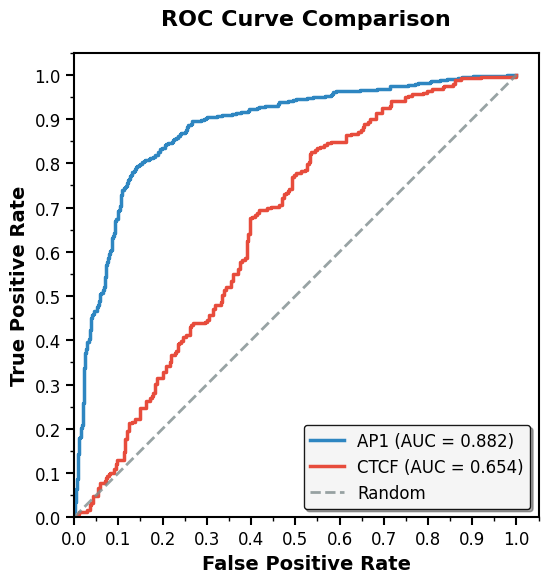

In [33]:
# Set up publication-quality plotting parameters
from matplotlib import rcParams

rcParams['font.family'] = 'DejaVu Sans'  # Adobe Illustrator recognizable font
rcParams['font.size'] = 12
rcParams['axes.linewidth'] = 1.5
rcParams['xtick.major.width'] = 1.5
rcParams['ytick.major.width'] = 1.5
rcParams['xtick.minor.width'] = 1.0
rcParams['ytick.minor.width'] = 1.0
rcParams['lines.linewidth'] = 2.0

# Create the figure and axis
fig, ax = plt.subplots(1, 1, figsize=(6, 6))

# Plot ROC curves
ax.plot(ap1_fpr, ap1_tpr, label=f'AP1 (AUC = {ap1_auc:.3f})', color='#2E86C1', linewidth=2.5)
ax.plot(ctcf_fpr, ctcf_tpr, label=f'CTCF (AUC = {ctcf_auc:.3f})', color='#E74C3C', linewidth=2.5)

# Plot diagonal line (random classifier)
ax.plot([0, 1], [0, 1], '--', color='#7F8C8D', linewidth=2.0, alpha=0.8, label='Random')

# Set labels and title
ax.set_xlabel('False Positive Rate', fontsize=14, fontweight='bold')
ax.set_ylabel('True Positive Rate', fontsize=14, fontweight='bold')
ax.set_title('ROC Curve Comparison', fontsize=16, fontweight='bold', pad=20)

# Set axis limits
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])

# Remove grid lines
ax.grid(False)

# Customize legend
legend = ax.legend(loc='lower right', frameon=True, fancybox=True, 
                   shadow=True, fontsize=12, framealpha=0.9)
legend.get_frame().set_facecolor('white')
legend.get_frame().set_edgecolor('black')
legend.get_frame().set_linewidth(1.0)

# Set tick parameters
ax.tick_params(axis='both', which='major', labelsize=12, width=1.5, length=6)
ax.tick_params(axis='both', which='minor', width=1.0, length=3)

# Add minor ticks
ax.set_xticks(np.arange(0, 1.1, 0.1), minor=False)
ax.set_yticks(np.arange(0, 1.1, 0.1), minor=False)
ax.set_xticks(np.arange(0, 1.1, 0.05), minor=True)
ax.set_yticks(np.arange(0, 1.1, 0.05), minor=True)

# Make the plot square
ax.set_aspect('equal', adjustable='box')

# Tight layout to prevent clipping
plt.tight_layout()

# Save as PDF with high quality
plt.savefig('roc_curve_comparison.pdf', format='pdf', dpi=300, 
            bbox_inches='tight', pad_inches=0.1, facecolor='white', 
            edgecolor='none')

# Display the plot
plt.show()

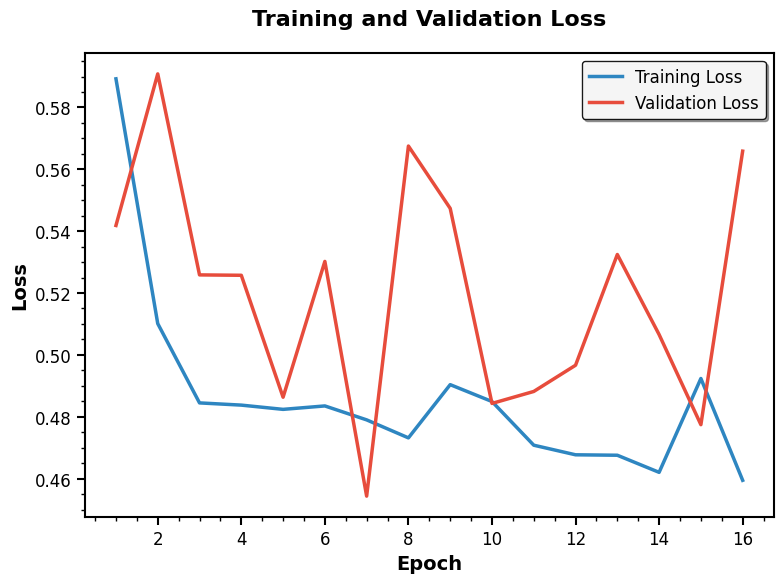

In [34]:
# Create epochs array
epochs = np.arange(1, len(history["train_loss"]) + 1)

# Plot 1: Training and Validation Loss
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

ax.plot(epochs, history["train_loss"], label='Training Loss', color='#2E86C1', linewidth=2.5)
ax.plot(epochs, history["val_loss"], label='Validation Loss', color='#E74C3C', linewidth=2.5)

# Set labels and title
ax.set_xlabel('Epoch', fontsize=14, fontweight='bold')
ax.set_ylabel('Loss', fontsize=14, fontweight='bold')
ax.set_title('Training and Validation Loss', fontsize=16, fontweight='bold', pad=20)

# Remove grid lines
ax.grid(False)

# Customize legend
legend = ax.legend(loc='upper right', frameon=True, fancybox=True, 
                   shadow=True, fontsize=12, framealpha=0.9)
legend.get_frame().set_facecolor('white')
legend.get_frame().set_edgecolor('black')
legend.get_frame().set_linewidth(1.0)

# Set tick parameters
ax.tick_params(axis='both', which='major', labelsize=12, width=1.5, length=6)
ax.tick_params(axis='both', which='minor', width=1.0, length=3)

# Add minor ticks
ax.minorticks_on()

# Tight layout
plt.tight_layout()

# Save as PDF
plt.savefig('training_validation_loss.pdf', format='pdf', dpi=300, 
            bbox_inches='tight', pad_inches=0.1, facecolor='white', 
            edgecolor='none')

plt.show()


In [ ]:
[0],epochs

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16])

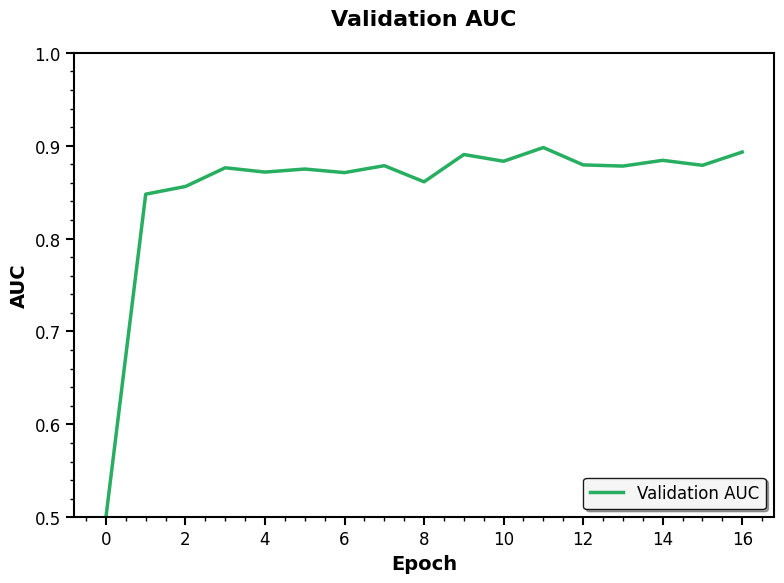

In [42]:

# Plot 2: Validation AUC
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

ax.plot(np.arange(0, 17), [0.5] + history["val_auc"], label='Validation AUC', color='#27AE60', linewidth=2.5)

# Set labels and title
ax.set_xlabel('Epoch', fontsize=14, fontweight='bold')
ax.set_ylabel('AUC', fontsize=14, fontweight='bold')
ax.set_title('Validation AUC', fontsize=16, fontweight='bold', pad=20)

# Set y-axis limits to better show AUC range (typically 0.5-1.0)
ax.set_ylim([0.5, 1.0])

# Remove grid lines
ax.grid(False)

# Customize legend
legend = ax.legend(loc='lower right', frameon=True, fancybox=True, 
                   shadow=True, fontsize=12, framealpha=0.9)
legend.get_frame().set_facecolor('white')
legend.get_frame().set_edgecolor('black')
legend.get_frame().set_linewidth(1.0)

# Set tick parameters
ax.tick_params(axis='both', which='major', labelsize=12, width=1.5, length=6)
ax.tick_params(axis='both', which='minor', width=1.0, length=3)

# Add minor ticks
ax.minorticks_on()

# Tight layout
plt.tight_layout()

# Save as PDF
plt.savefig('validation_auc.pdf', format='pdf', dpi=300, 
            bbox_inches='tight', pad_inches=0.1, facecolor='white', 
            edgecolor='none')

plt.show()